### MODULE 1 : Original Photograph

### Objectives
Extract the dimensions, channel count, and file size, then display the image.

### Technique Used
OpenCV reads the image into a matrix in BGR format, extracting the shape properties from the array, while the OS library calculates the file size on disk.

--- Task 1: Image Properties ---
Dimensions (width x height): 4624 x 2600
Number of color channels: 3
File size: 3.26 MB


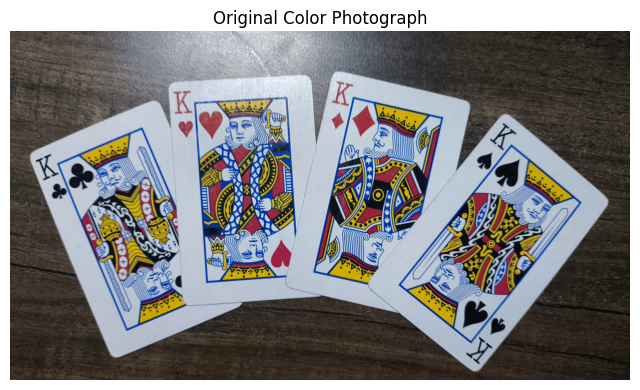

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Define your image filename here
file_path = "my_photograph.jpg"

img_bgr = cv2.imread(file_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

height, width, num_channels = img_bgr.shape
file_size_mb = os.path.getsize(file_path) / (1024 * 1024)

print("--- Task 1: Image Properties ---")
print(f"Dimensions (width x height): {width} x {height}")
print(f"Number of color channels: {num_channels}")
print(f"File size: {file_size_mb:.2f} MB")

plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title("Original Color Photograph")
plt.axis("off")
plt.show()

### Settings Used
No image-processing filters were applied. The cv2.COLOR_BGR2RGB conversion flag was utilized to ensure the color channels display correctly in Matplotlib.
### Observation
The raw photograph is loaded and plotted successfully. It remains entirely unchanged, establishing the structural and chromatic baseline required to evaluate all subsequent processing techniques.

### MODULE 2 : Grayscale Conversion
### Objectives
To convert the color photograph into different shades of gray to make the image simpler to work with for further processing while keeping brightness details visible.

### Technique Used
Grayscale conversion collapses the 3-channel color photograph into a single-channel image, removing hue and saturation while preserving luminance.

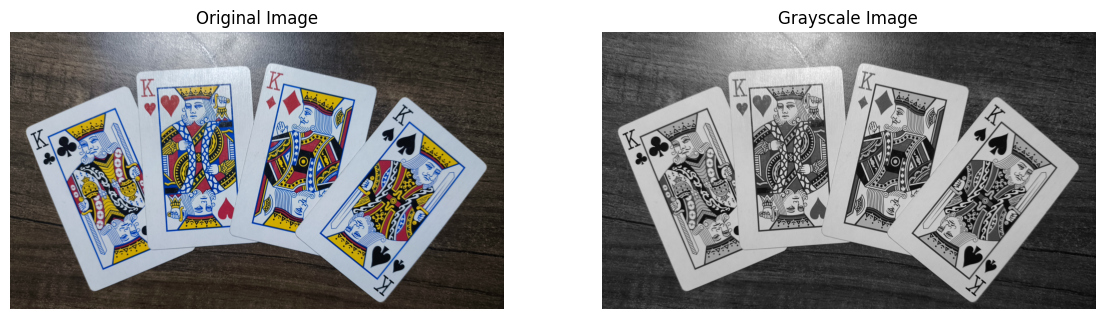

In [12]:
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(img_rgb)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(img_gray, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Grayscale Image")
ax[1].axis("off")
plt.show()

### Settings Used
The original BGR image was passed through OpenCV using the cv2.COLOR_BGR2GRAY parameter. Matplotlib's cmap="gray" was set with vmin=0 and vmax=255 to ensure the output rendered in true grayscale.

### Observation
All original color data is replaced by varying shades of gray. Despite the loss of color, the underlying structural integrity—including object boundaries, shadow gradients, and fine surface details—remains intact and identifiable

##MODULE 3 : Negative and Gamma Transformations
###Objective:
To observe how changing pixel intensities affects the overall appearance of the photograph through reversing brightness and applying targeted brightening or darkening adjustments.
###Technique Used:
The negative transformation reverses pixel brightness by subtracting the current intensity from the maximum 8-bit value (255). Gamma correction applies a power-law transformation ($s = r^\gamma$) to non-linearly adjust image brightness.

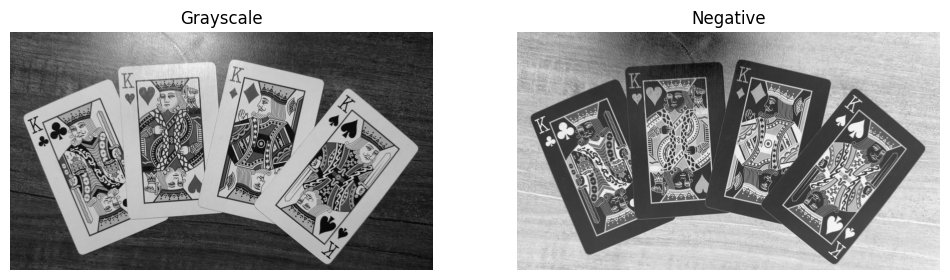

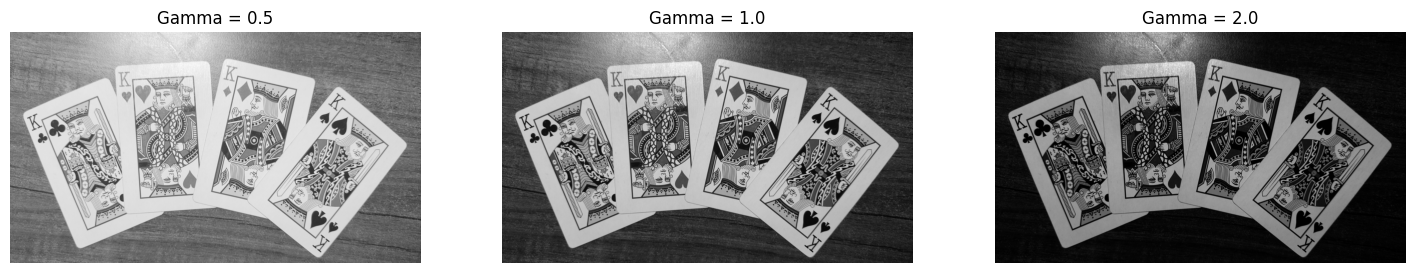

In [13]:
# Negative
img_negative = 255 - img_gray

# Gamma Correction setup
img_norm = img_gray.astype(np.float32) / 255.0
gammas = [0.5, 1.0, 2.0]
gamma_results = []

for g in gammas:
    transformed = np.power(img_norm, g)
    transformed_uint8 = np.clip(transformed * 255.0, 0, 255).astype(np.uint8)
    gamma_results.append(transformed_uint8)

# Plotting Negative
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img_gray, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Grayscale"); ax[0].axis("off")
ax[1].imshow(img_negative, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Negative"); ax[1].axis("off")
plt.show()

# Plotting Gammas
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, g in enumerate(gammas):
    ax[i].imshow(gamma_results[i], cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(f"Gamma = {g}")
    ax[i].axis("off")
plt.show()

###Settings Used:
Pixel values were normalized to a $[0, 1]$ floating-point range before applying the exponential gamma values of 0.5, 1.0, and 2.0. Values were then clipped and converted back to an 8-bit $[0, 255]$ integer scale for rendering.
###Observation:
The negative output effectively inverts the image, turning shadowed areas bright and illuminated areas dark. The 0.5 gamma parameter brightens the image significantly, exposing details hidden in shadows. The 1.0 parameter leaves the image unaltered, while the 2.0 parameter aggressively darkens the photograph, crushing low-intensity details.  

###MODULE 4 : Contrast Enhancement And Histogram
###Objective:
To improve image visibility by separating darker and brighter areas, making details easier to distinguish.
###Technique Used:
Linear contrast stretching maps the image's specific minimum and maximum pixel values to the absolute 0 and 255 limits, pulling the intermediate values apart linearly. Global histogram equalization flattens the image's cumulative frequency distribution, non-linearly remapping pixels to utilize the entire intensity spectrum.

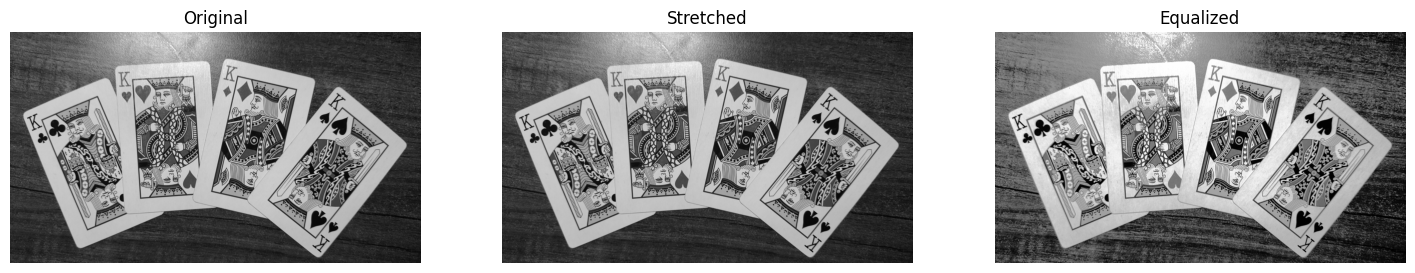

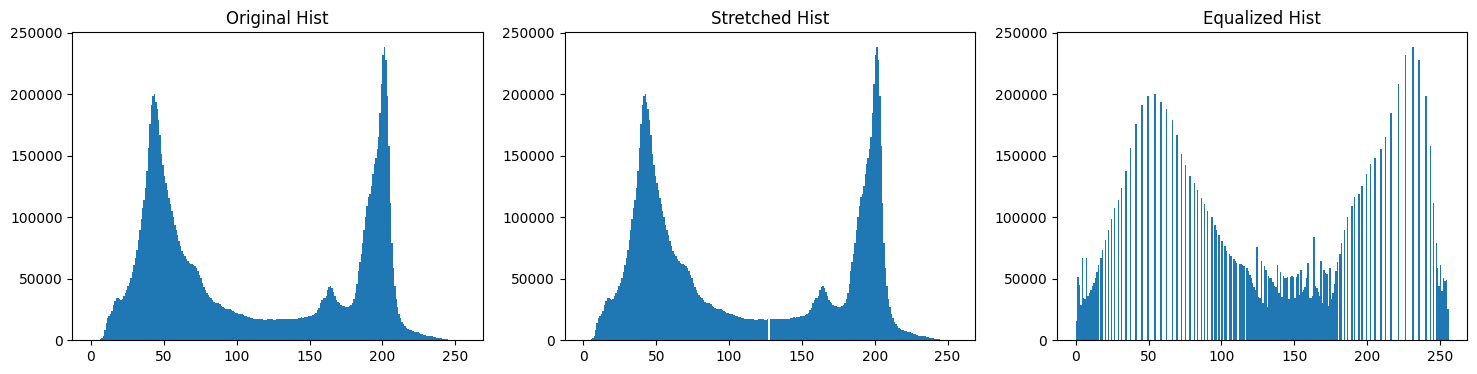

In [14]:
# Linear Contrast Stretching
min_px = np.min(img_gray)
max_px = np.max(img_gray)

if max_px > min_px:
    img_stretched = ((img_gray.astype(np.float32) - min_px) * 255.0 / (max_px - min_px))
    img_stretched = np.clip(img_stretched, 0, 255).astype(np.uint8)
else:
    img_stretched = img_gray.copy()

# Global Histogram Equalization
img_eq = cv2.equalizeHist(img_gray)

# Plot Images
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(img_gray, cmap="gray"); ax[0].set_title("Original"); ax[0].axis("off")
ax[1].imshow(img_stretched, cmap="gray"); ax[1].set_title("Stretched"); ax[1].axis("off")
ax[2].imshow(img_eq, cmap="gray"); ax[2].set_title("Equalized"); ax[2].axis("off")
plt.show()

# Plot Histograms
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].hist(img_gray.flatten(), bins=256, range=[0, 256]); ax[0].set_title("Original Hist")
ax[1].hist(img_stretched.flatten(), bins=256, range=[0, 256]); ax[1].set_title("Stretched Hist")
ax[2].hist(img_eq.flatten(), bins=256, range=[0, 256]); ax[2].set_title("Equalized Hist")
plt.show()

###Settings Used:
Linear stretching utilized np.min() and np.max() to determine mathematical bounds for scaling. Global equalization was executed via OpenCV's cv2.equalizeHist(). Histograms were visualized using 256 bins constrained to the $0-256$ intensity range to ensure equivalent visual comparisons.
###Observation:
The stretched histogram visibly expands outward compared to the original, which linearly improves the distinction between light and dark elements. The equalized histogram is drastically redistributed, which maximizes global contrast but can introduce harsh lighting or emphasize image noise.

###MODULE 5 : Gaussian Smoothing
###Objective:
To reduce noise and soften fine details in the image to observe how different kernel sizes affect sharpness and object boundaries.   ###Technique Used:
Gaussian smoothing mitigates image noise by running a weighted averaging filter over the image matrix. The filter assigns highest mathematical weights to the center pixel of the kernel, yielding a smooth, organic blur.

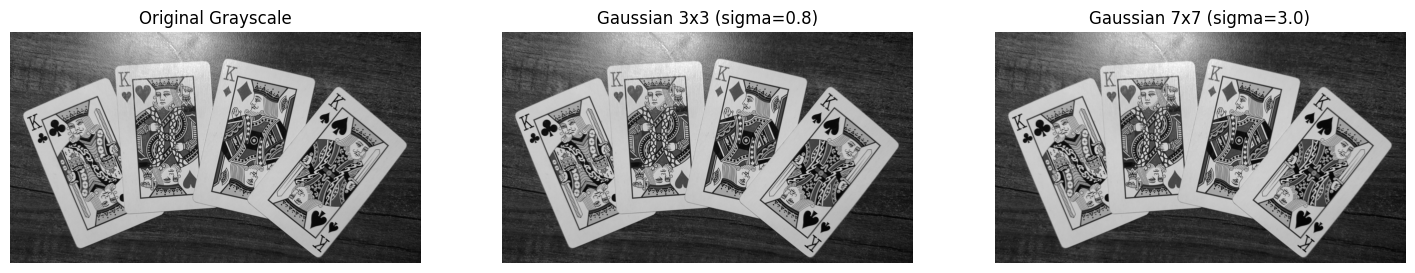

In [15]:
gauss_3x3 = cv2.GaussianBlur(img_gray, (3, 3), sigmaX=0.8)
gauss_7x7 = cv2.GaussianBlur(img_gray, (7, 7), sigmaX=3.0)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(img_gray, cmap="gray"); ax[0].set_title("Original Grayscale"); ax[0].axis("off")
ax[1].imshow(gauss_3x3, cmap="gray"); ax[1].set_title("Gaussian 3x3 (sigma=0.8)"); ax[1].axis("off")
ax[2].imshow(gauss_7x7, cmap="gray"); ax[2].set_title("Gaussian 7x7 (sigma=3.0)"); ax[2].axis("off")
plt.show()

###Settings Used:
The cv2.GaussianBlur() function was applied using a $3\times3$ kernel with a standard deviation (sigmaX) of 0.8, and a $7\times7$ kernel with a standard deviation of 3.0.
###Observation:
The $3\times3$ kernel induces a very subtle reduction in sharpness, keeping primary object structures and boundaries cleanly intact. The $7\times7$ kernel aggregates a much wider neighborhood of pixels, generating an aggressive blur that heavily softens edges and erases minute structural textures.  

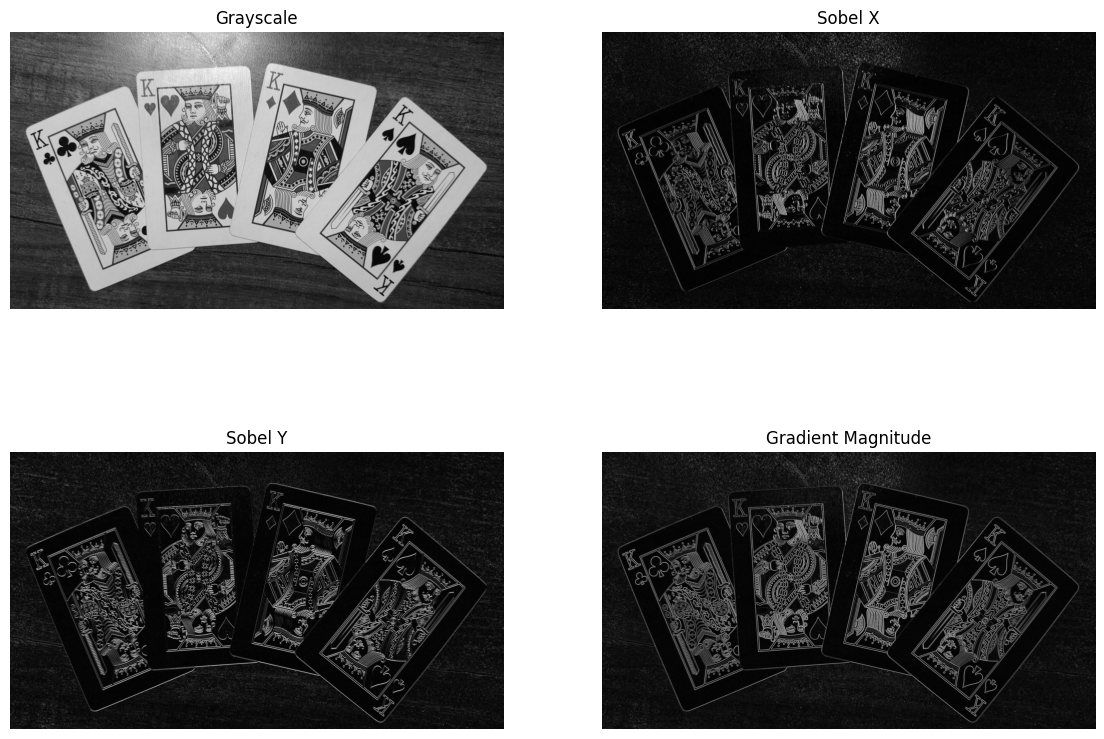

In [16]:
sobel_x = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)

abs_sobel_x = np.abs(sobel_x)
abs_sobel_y = np.abs(sobel_y)
grad_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

def scale_edges(matrix):
    p99 = np.percentile(matrix, 99)
    if p99 <= 0: return np.zeros_like(matrix, dtype=np.uint8)
    scaled = np.clip((matrix / p99) * 255.0, 0, 255)
    return scaled.astype(np.uint8)

disp_x = scale_edges(abs_sobel_x)
disp_y = scale_edges(abs_sobel_y)
disp_mag = scale_edges(grad_magnitude)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0,0].imshow(img_gray, cmap="gray"); ax[0,0].set_title("Grayscale"); ax[0,0].axis("off")
ax[0,1].imshow(disp_x, cmap="gray"); ax[0,1].set_title("Sobel X"); ax[0,1].axis("off")
ax[1,0].imshow(disp_y, cmap="gray"); ax[1,0].set_title("Sobel Y"); ax[1,0].axis("off")
ax[1,1].imshow(disp_mag, cmap="gray"); ax[1,1].set_title("Gradient Magnitude"); ax[1,1].axis("off")
plt.show()

###MODULE 6 : Edge Detection (Sobel Operators)
###Objective:
To identify object boundaries by detecting sudden changes in pixel intensity across horizontal and vertical axes.
###Technique Used:
Sobel operators calculate the spatial gradient of pixel intensities. Sobel X measures horizontal changes to locate vertical edges, and Sobel Y measures vertical changes to isolate horizontal edges. Both responses are combined to produce an overall gradient magnitude map.   

###Settings Used:
Gradients were calculated with a $3\times3$ kernel using the cv2.CV_64F data type, which prevents the mathematical clipping of negative gradient slopes during extraction. The final display arrays were normalized to an 8-bit range, utilizing the 99th percentile as the upper reference value to limit the effect of unusually large gradient values,
###Observation:
The Sobel X response successfully traces vertical architectural lines, while Sobel Y extracts horizontal changes. The combined magnitude map merges these vectors to clearly highlight structural borders while dropping low-variance, uniform textures into black.